# 04. 学習用データセットの作成

**このノートブックで行なったこと**

03で決めた変換条件で 全554エピソードを変換し、模倣学習に使うデータセットを作る。
学習する方策はACTとDiffusion Policy（DP）の2種類とした。

| データセット | 選別 | 使う方策 |
|---|---|---|
| 基本版`so101_lerobot_dataset` | IK成功率80%以上 | ACT |
| 手首カメラ選別版`so101_lerobot_dataset_wristcam` | 上記 ＋ 手首カメラの向きによる選別 | DP |

なお、手首カメラの向きによる選別は、試行錯誤の過程でACTの学習の後に追加した工程となっている。
ACTは基本版で、DPはこの選別を加えたデータセットで行った。

1. 全エピソードをリターゲットする（03と同じ関数・同じ条件）
2. IK成功率が低いエピソードを除外する（基本版）
3. 手首カメラがロボット自身の腕の方を向いてしまうエピソードを除外する（手首カメラ選別版）
4. 手元カメラ映像から、IKが成功したフレームに対応する画像を取り出す
5. LeRobot v3.0形式（lerobot 0.6.1が読み込める形式）で保存する
6. 保存したデータセットをlerobotで読み込めること、学習時のデータセットと条件が一致することを確かめる


In [1]:
# パス設定
from pathlib import Path

ROOT = Path.cwd()
DATA_DIR = ROOT / "data"        # 外部から取得したデータの置き場所
OUT_DIR = ROOT / "outputs"      # このノートブックで作成する図・動画の置き場所

# Grabetteデータセット
GRABETTE_DIR = DATA_DIR / "grabette_pick3_cartesian_480"

# SO-101のMuJoCoモデル
MENAGERIE_DIR = DATA_DIR / "mujoco_menagerie"
MJCF_PATH = MENAGERIE_DIR / "robotstudio_so101" / "so101.xml"
# 描画用のシーン
SCENE_PATH = MENAGERIE_DIR / "robotstudio_so101" / "scene.xml"

OUT_DIR.mkdir(parents=True, exist_ok=True)
# print("ROOT         :", ROOT)
# print("GRABETTE_DIR :", GRABETTE_DIR)
# print("MJCF_PATH    :", MJCF_PATH)

In [2]:
# グラフスタイル設定

# 系列の色は固定順で割り当てる（1:青, 2:橙, 3:緑青, 4:黄, 5:桃, 6:緑, 7:紫, 8:赤）。
# 成功/失敗などの「状態」には、系列色とは別に専用の2色を使う。
import matplotlib.pyplot as plt
import japanize_matplotlib

SERIES_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
                 "#e87ba4", "#008300", "#6250d6", "#e34948"]
COLOR_GOOD = "#0ca30c"      # 成功・採用を表す色
COLOR_BAD = "#d03b3b"       # 失敗・除外を表す色
COLOR_MUTED = "#898781"     # 補助線・参考情報の色

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.color": "#e1e0d9",
    "grid.linewidth": 0.6,
    "axes.edgecolor": "#c3c2b7",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "lines.linewidth": 2.0,
    "legend.frameon": False,
})

In [3]:
# Grabetteデータの読み込み
import numpy as np
import pandas as pd

grabette_frames = pd.read_parquet(
    GRABETTE_DIR / "data" / "chunk-000" / "file-000.parquet"
) # データ長

grabette_episodes = pd.read_parquet(
    GRABETTE_DIR / "meta" / "episodes" / "chunk-000" / "file-000.parquet"
) # エピソード単位のメタ情報
EPISODE_IDS = sorted(grabette_frames["episode_index"].unique())
GRABETTE_FPS = 50   # meta/info.jsonの"fps"。数値データ・動画ともに50fps

def get_episode(episode_id):
    """
    1エピソード分のactionとis_lostを取り出す。

    戻り値
    ------
    actions : (T, 11)のfloat64配列
        列0-2 : カメラ座標系での位置の変化量dx, dy, dz [m]
        列3-8 : 姿勢の変化量（6D回転表現）
        列9   : グリッパーのproximal関節角[rad]（大きいほど閉じている）
        列10  : グリッパーのdistal関節角[rad]（本研究では使用しない）
    is_lost : (T,)のbool配列
        TrueのフレームはSLAM（自己位置推定）が位置を見失っている
    """
    rows = grabette_frames[grabette_frames["episode_index"] == episode_id]
    actions = np.array(rows["action"].tolist(), dtype=float)
    is_lost = rows["is_lost"].to_numpy().astype(bool)
    return actions, is_lost

In [4]:
# Grabetteデータの読み込み

# 複数エピソードが1本のmp4につながっている。
# エピソード情報のfrom_timestamp（そのエピソードの開始時刻）に「フレーム番号/50fps」を足した時刻のフレームをlerobotの動画読み込み関数で取り出す。
from lerobot.datasets.video_utils import decode_video_frames_pyav

VIDEO_KEY = "observation.images.cam0" # カメラのキー
episodes_meta = grabette_episodes.set_index("episode_index") # メタデータをエピソード番号でキーに

def grabette_video_frames(episode_id, frame_indices):
    """エピソード内のフレーム番号の並びに対応する映像フレーム(N, H, W, 3)を返す。"""
    row = episodes_meta.loc[episode_id]
    chunk = int(row[f"videos/{VIDEO_KEY}/chunk_index"])
    file = int(row[f"videos/{VIDEO_KEY}/file_index"])
    start = float(row[f"videos/{VIDEO_KEY}/from_timestamp"])
    path = (GRABETTE_DIR / "videos" / VIDEO_KEY / f"chunk-{chunk:03d}"
            / f"file-{file:03d}.mp4")
    times = [float(start + i / GRABETTE_FPS) for i in frame_indices]
    frames = decode_video_frames_pyav(path, times,
                                      tolerance_s=1.5 / GRABETTE_FPS,
                                      return_uint8=True)
    return frames.permute(0, 2, 3, 1).numpy()   # (N, C, H, W) → (N, H, W, C)

In [5]:
# ============================================================
# 変化量（デルタ）を積算して絶対軌跡を復元する関数
# ============================================================
# Grabetteのactionは「1フレーム前からどれだけ動いたか」を、
# 1フレーム前のカメラ自身の向きを基準に記録したものである。
# そのため、次の2式を先頭フレームから順に繰り返すと、絶対的な位置と姿勢が得られる。
#
#     位置: p[t+1] = p[t] + R[t] @ dp[t]   （dpを現在の向きR[t]で回してから足す）
#     姿勢: R[t+1] = R[t] @ dR[t]
#
# 先頭フレームは「位置 = 原点」「姿勢 = 単位行列」とする。
# つまり、復元される軌跡は「撮影開始時のカメラ座標系」で表された軌跡になる。


def r6d_to_matrix(r6d):
    """
    6D回転表現（回転行列の1列目と2列目を並べたもの）を3x3回転行列に戻す。

    Gram-Schmidtの直交化で1列目と2列目を直交する単位ベクトルに整え、
    3列目はその外積として求める。
    """
    r6d = np.asarray(r6d, dtype=float)
    shape = r6d.shape[:-1]
    r6d = r6d.reshape(-1, 6)

    a1 = r6d[:, :3]
    a2 = r6d[:, 3:6]

    # 1列目: a1を長さ1に正規化する（長さが0に近い場合は割り算しない）
    norm_a1 = np.linalg.norm(a1, axis=-1, keepdims=True)
    b1 = a1 / np.where(norm_a1 > 1e-8, norm_a1, 1.0)

    # 2列目: a2からb1方向の成分を取り除き、長さ1に正規化する
    b2 = a2 - (b1 * a2).sum(axis=-1, keepdims=True) * b1
    norm_b2 = np.linalg.norm(b2, axis=-1, keepdims=True)
    b2 = b2 / np.where(norm_b2 > 1e-8, norm_b2, 1.0)

    # 3列目: 右手系になるように外積で求める
    b3 = np.cross(b1, b2)

    rotation = np.stack([b1, b2, b3], axis=-1)
    return rotation.reshape(*shape, 3, 3) if shape else rotation[0]


def accumulate_deltas(actions):
    """
    actionの位置・姿勢の変化量を積算し、絶対軌跡を返す。

    戻り値の長さはT+1である。
    添字0は「動き出す前の初期状態」、添字t+1は「t番目の変化量を
    適用した後の状態」を表す。各フレームの位置として使うときは[1:]を取る。
    """
    actions = np.asarray(actions, dtype=float)
    n_frames = len(actions)

    positions = np.zeros((n_frames + 1, 3))
    rotations = np.zeros((n_frames + 1, 3, 3))
    positions[0] = np.zeros(3)      # 初期位置は原点
    rotations[0] = np.eye(3)        # 初期姿勢は単位行列

    for t in range(n_frames):
        delta_position = actions[t, :3]
        delta_rotation = r6d_to_matrix(actions[t, 3:9])

        positions[t + 1] = positions[t] + rotations[t] @ delta_position
        rotations[t + 1] = rotations[t] @ delta_rotation

        # 掛け算を繰り返すと浮動小数点誤差で回転行列が少しずつ歪むため、
        # 特異値分解で最も近い回転行列に毎回戻しておく
        u, _, vt = np.linalg.svd(rotations[t + 1])
        rotations[t + 1] = u @ vt

    return positions, rotations

In [6]:
# ============================================================
# カメラ座標系 → ロボット座標系 の変換行列
# ============================================================
# Grabetteのカメラ（OAK-D）は一般的なカメラ座標系の規約に従う。
#     カメラX = 右,  カメラY = 下,  カメラZ = 前（奥行き）
# 一方、SO-101（MuJoCoモデル）の座標系は次のとおりである。
#     ロボットX = 前,  ロボットY = 左,  ロボットZ = 上
# この対応を行列で表すと次のようになる（各行が「ロボットの軸 = カメラの軸の組合せ」）。
#     ロボットX =  カメラZ
#     ロボットY = -カメラX
#     ロボットZ = -カメラY
R_CAM_TO_ROBOT = np.array(
    [[0, 0, 1],
     [-1, 0, 0],
     [0, -1, 0]], dtype=float
)

In [7]:
import numpy as np

# 関節の並び順はMJCFの定義順と同じであり、学習データの列順もこれに従う。
JOINT_NAMES = ["shoulder_pan", "shoulder_lift", "elbow_flex",
               "wrist_flex", "wrist_roll", "gripper"]

# 以下SO-101姿勢に関する「決め打ち」の値。何回か試行錯誤の末、目測上破綻のない姿勢をとらせることにした。

# 手首の回転（wrist_roll）を固定する値: -90度
# この角度では、ジョーがロボットの左右方向（Y方向）に開く。
# Grabetteの映像でも2本の指は画面の左右にあり、物体を左右から挟む。その向きに合わせる。
WRIST_ROLL_FIXED = -np.pi / 2

# 初期姿勢（決め打ち）。IKを解き始める最初の関節角として使う。
Q_INIT_PICK = np.array([
    0.0,                 # shoulder_pan : 正面を向く
    np.radians(-10.0),   # shoulder_lift: 上腕をわずかに前へ倒す
    np.radians(15.0),    # elbow_flex   : 肘を少し曲げる
    np.radians(85.0),    # wrist_flex   : 手首を曲げてグリッパーの先端を下ろす
    WRIST_ROLL_FIXED,    # wrist_roll   : -90度（ジョーが左右に開く向き）
    0.0,                 # gripper      : IKでは動かさない関節なので値は使われない
], dtype=float)

# 作業空間の中心。初期姿勢Q_INIT_PICKのグリッパー位置（約[0.211, -0.012, 0.067]）の近くに置くことで、
# 軌跡の中心付近では初期姿勢のままIKが解けるようにしている。
WORKSPACE_CENTER = np.array([0.22, 0.0, 0.07])

# IKが収束しなかったときに、初期値を変えて解き直すための予備の初期姿勢。
Q_INIT_FALLBACKS = [
    np.array([0, np.radians(-15), np.radians(10), np.radians(85),
              WRIST_ROLL_FIXED, 0], dtype=float),
    np.array([0, np.radians(-20), np.radians(20), np.radians(80),
              WRIST_ROLL_FIXED, 0], dtype=float),
    np.array([0, np.radians(-5), np.radians(10), np.radians(80),
              WRIST_ROLL_FIXED, 0], dtype=float),
]

# グリッパー関節角とジョーの開き具合の対応（MuJoCoで実測。02で確認する）
SO101_GRIPPER_OPEN = 1.7453292    # 全開（ジョー間隔 約133 mm）
SO101_GRIPPER_CLOSED = 0.0        # 全閉（ジョー間隔 約16 mm）

In [8]:
# FK・IK計算関数群
# 計算ライブラリにはpinocchioを用いる
import pinocchio as pin

EE_FRAME = "gripperframe"     # グリッパー先端を表すMJCF上の名前

class SO101Kinematics:
    """SO-101（腕5関節 + グリッパー1関節）のFK / IKを計算するクラス。"""

    def __init__(self, mjcf_path):
        # MJCFからロボットモデルを作成し、計算用の作業領域（data）を確保する
        self.model = pin.buildModelFromMJCF(str(mjcf_path))
        self.data = self.model.createData()
        self.ee_id = self.model.getFrameId(EE_FRAME)
        # 関節の並び順が想定どおりかを確認する（違えば以降の計算がすべて狂う）
        names = [self.model.names[i] for i in range(1, self.model.njoints)]
        if names != JOINT_NAMES:
            raise ValueError(f"関節の並び順が想定と異なります: {names}")

    def joint_limits(self):
        """各関節の可動範囲（下限, 上限）[rad]を返す。"""
        return (self.model.lowerPositionLimit.copy(),
                self.model.upperPositionLimit.copy())

    def ik(self, target, q_init=None, max_iters=200, pos_tol=1e-4,
           rot_tol=1e-2, step=1.0, damping=1e-6, pos_weight=1.0,
           ori_weight=1e-4, locked_joints=(5,), history=None):
        """
        逆運動学: 目標target（pin.SE3）に届く関節角を反復計算で探す。

        計算の流れ（1回の反復）
        ------------------------
        1. 現在の関節角qでFKを計算し、グリッパー先端の現在位置を求める。
        2. 「現在 → 目標」のずれerr（位置3成分 + 姿勢3成分）を求める。
        3. ずれに重みを掛ける。位置の重みは1、姿勢の重みは1e-4とする。
           SO-101は腕が5関節しかなく、位置3 + 姿勢3の6自由度すべてを
           同時に合わせることは一般にできない。そこで姿勢はほぼ無視し、
           位置を合わせることを優先する。
        4. ヤコビアンJ（関節を少し動かすと先端がどれだけ動くかを表す行列）を使い、
           減衰付き最小二乗法で関節の修正量dqを求める。
               dq = Jw^T (Jw Jw^T + damping * I)^(-1) err_w
           dampingはJがほぼ特異（どの方向にも動けない姿勢）なときに
           dqが極端に大きくなるのを防ぐための小さな値である。
        5. qをdqだけ更新し、関節の可動範囲内に収める（範囲外の値は端に揃える）。

        locked_jointsに指定した関節（既定ではグリッパー）はJの列を0にするため、
        IKでは一切動かず、q_initの値のまま残る。

        引数historyにリストを渡すと、反復ごとの位置誤差[m]を記録する
        （収束の様子を図示するための補助機能で、計算結果には影響しない）。

        戻り値
        ------
        q        : (6,)最終的な関節角
        success  : 位置誤差がpos_tol未満ならTrue
        pos_err  : 最終的な位置誤差[m]（FKで計算し直した値）
        """
        if q_init is not None:
            q = q_init.copy().astype(float)
        else:
            # 初期値が無い場合は、全関節0（pinocchioの基準姿勢）から始める
            q = pin.neutral(self.model).astype(float)
        weight = np.diag([pos_weight] * 3 + [ori_weight] * 3)

        for _ in range(max_iters):
            # 手順1: 現在の先端位置
            pin.forwardKinematics(self.model, self.data, q)
            pin.updateFramePlacements(self.model, self.data)
            current = self.data.oMf[self.ee_id]

            # 手順2: 現在から目標までのずれ（先端自身の座標系で表した6成分）
            err = pin.log6(current.actInv(target)).vector
            pos_err = float(np.linalg.norm(err[:3]))
            if history is not None:
                history.append(pos_err)
            # 位置・姿勢とも十分に小さければ反復を打ち切る
            # （姿勢の重みが小さいため、実際には上限回数まで回ることが多い）
            if pos_err < pos_tol and np.linalg.norm(err[3:]) < rot_tol:
                break

            # 手順3: 重み付け
            err_w = weight @ err

            # 手順4: ヤコビアンと減衰付き最小二乗法
            jac = pin.computeFrameJacobian(self.model, self.data, q,
                                           self.ee_id, pin.LOCAL)
            for j in locked_joints:
                jac[:, j] = 0.0
            jac_w = weight @ jac
            dq = jac_w.T @ np.linalg.solve(
                jac_w @ jac_w.T + damping * np.eye(6), err_w)

            # 手順5: 更新と可動範囲への制限
            q = pin.integrate(self.model, q, step * dq)
            q = np.clip(q, self.model.lowerPositionLimit,
                        self.model.upperPositionLimit)

        # 最終結果をFKで確かめ直し、目標との位置の差を誤差とする
        pin.forwardKinematics(self.model, self.data, q)
        pin.updateFramePlacements(self.model, self.data)
        pos_err = float(np.linalg.norm(
            self.data.oMf[self.ee_id].translation - target.translation))
        return q, pos_err < pos_tol, pos_err

In [9]:
# グリッパー角の変換: Grabette proximal → SO-101 gripper

# 02で確認した通り、GrabetteのproximalとSO-101のgripper角は正負が逆転している。
# 下記関数にて、各エピソード内の最小値を「全開」、最大値を「全閉」とみなして
# 0〜1の比率に直し、SO-101の角度へ線形に割り当てる。

def proximal_to_so101(proximal, ep_prox_min, ep_prox_max):
    """
    proximal角[rad]をSO-101のgripper角[rad]に変換する。

    比率ratio = (proximal - エピソード最小値) / (エピソード最大値 - エピソード最小値)
        ratio = 0 → 手が最も開いている → SO-101全開（1.745 rad）
        ratio = 1 → 手が最も閉じている → SO-101全閉（0 rad）
    """
    proximal = np.asarray(proximal, dtype=float)
    denom = float(ep_prox_max) - float(ep_prox_min)
    if abs(denom) < 1e-6:
        # エピソード中に一度も開閉していない場合は、全開のままとする
        return np.full_like(proximal, SO101_GRIPPER_OPEN)
    ratio = np.clip((proximal - float(ep_prox_min)) / denom, 0.0, 1.0)
    return SO101_GRIPPER_OPEN + ratio * (SO101_GRIPPER_CLOSED
                                         - SO101_GRIPPER_OPEN)

In [10]:
# ガウス平滑化にはscipyの関数を使う
from scipy.ndimage import gaussian_filter1d

# ============================================================
# リターゲット: Grabetteの1エピソード → SO-101の関節角の時系列
# ============================================================
# 手首を180度ひっくり返す回転（グリッパーの進行方向の軸まわり）。
# Grabetteの姿勢をそのまま目標にすると、手首カメラがテーブル側を向く姿勢が
# 選ばれやすいため、目標姿勢にこの回転を掛けておく。
R_WRIST_FLIP = np.array(
    [[-1, 0, 0],
     [0, -1, 0],
     [0, 0, 1]], dtype=float
)

# 以下SO-101変換に関する「決め打ち」の値。何回か試行錯誤の末、目測上破綻のない値をとらせることにした。

# Grabetteの軌跡をSO-101の大きさに合わせる縮小率。0.75倍
SCALE_FACTOR = 0.75
# 関節角の平滑化の強さ（ガウス平滑化の標準偏差 [フレーム]）
SMOOTH_SIGMA = 8.0
# 1フレームあたりに許す関節角の最大変化量 [度]
MAX_DQ_DEG = 8.0
# IK成功とみなす位置誤差の上限[m]（5 mm）
POS_TOL = 5e-3

def retarget_episode(actions, is_lost, kin, scale_factor=SCALE_FACTOR,
                     workspace_center=WORKSPACE_CENTER,
                     smooth_sigma=SMOOTH_SIGMA, max_dq_deg=MAX_DQ_DEG,
                     pos_tol=POS_TOL):
    """
    Grabetteの1エピソードをSO-101の関節角の時系列に変換する。

    処理の手順
    ----------
    1. 変化量を積算して絶対軌跡（カメラ座標系）を得る
    2. カメラ座標系 → ロボット座標系 に変換する
    3. 目標姿勢に手首反転R_WRIST_FLIPを掛ける
    4. 軌跡を縮小し、重心を作業空間の中心に合わせる
    5. グリッパー角を変換する
    6. フレームごとにIKを解く（失敗したら初期値を変えて解き直す）
    7. 関節角の急な変化を抑え、平滑化する

    戻り値（dict）
    --------------
    joint_angles : (T, 6)関節角[rad]。SLAM喪失フレームはNaN
    valid_mask   : (T,) IKが成功したフレームならTrue
    pos_errors   : (T,) IKの位置誤差[m]（解いていないフレームはinf）
    ee_positions : (T, 3) IKの目標とした先端位置[m]
    ik_source    : (T,)どの初期値で最終解が得られたか（説明・図示用）
                   "warm"=前フレーム, "init"=初期姿勢/予備姿勢,
                   "neutral"=全関節0, "random"=乱数, "lost"=SLAM喪失
    """
    n_frames = len(actions)
    joint_angles = np.full((n_frames, 6), np.nan)
    valid_mask = np.zeros(n_frames, dtype=bool)
    pos_errors = np.full(n_frames, np.inf)
    ik_source = np.array(["lost"] * n_frames, dtype=object)

    # ---- 手順1: 絶対軌跡。添字0は初期状態なので除いて長さTに揃える ----
    positions_full, rotations_full = accumulate_deltas(actions)
    positions = positions_full[1:]
    rotations = rotations_full[1:]

    # ---- 手順2: カメラ座標系 → ロボット座標系 ----
    positions = (R_CAM_TO_ROBOT @ positions.T).T
    rotations = np.einsum("ij,tjk->tik", R_CAM_TO_ROBOT, rotations)

    # ---- 手順3: 手首反転（姿勢の右から掛ける = 先端自身の軸まわりの回転） ----
    rotations = np.einsum("tij,jk->tik", rotations, R_WRIST_FLIP)

    # ---- 手順4: 縮小と中心合わせ ----
    #   目標位置 = (元の位置 - 軌跡の重心) * 縮小率 + 作業空間の中心
    trajectory_mean = positions.mean(axis=0)
    ee_positions = ((positions - trajectory_mean) * scale_factor
                    + workspace_center)

    # ---- 手順5: グリッパー角（エピソード内の最小/最大で正規化） ----
    gripper_angle = proximal_to_so101(actions[:, 9],
                                      ep_prox_min=actions[:, 9].min(),
                                      ep_prox_max=actions[:, 9].max())

    # ---- 手順6: フレームごとのIK ----
    lower, upper = kin.joint_limits()
    rng = np.random.default_rng(0)     # 乱数の初期値を固定し、毎回同じ結果にする
    q_prev = Q_INIT_PICK.copy()        # 最初のフレームは決め打ちの初期姿勢から解く

    for t in range(n_frames):
        if is_lost[t]:
            # SLAMが位置を見失ったフレームは目標位置が信用できないので解かない
            continue

        target = pin.SE3(rotations[t], ee_positions[t])

        # (a)前フレームの解を初期値にする（ウォームスタート）。
        #     隣り合うフレームの目標は近いので、通常はこれで収束し、
        #     腕の構え（解の枝）も前フレームから連続したものになる。
        q_sol, ok, err = kin.ik(target, q_init=q_prev.copy(), pos_tol=pos_tol)
        source = "warm"

        # (b)失敗したら、決め打ちの初期姿勢と予備姿勢から順に解き直す。
        #     誤差が小さくなった解だけを採用し、成功した時点で打ち切る。
        if not ok:
            for q_try in [Q_INIT_PICK.copy()] + [q.copy()
                                                 for q in Q_INIT_FALLBACKS]:
                q_sol2, ok2, err2 = kin.ik(target, q_init=q_try,
                                           pos_tol=pos_tol)
                if err2 < err:
                    q_sol, ok, err = q_sol2, ok2, err2
                    source = "init"
                if ok:
                    break

        # (c)それでも失敗したら、全関節0の姿勢から解き直す
        if not ok:
            q_sol3, ok3, err3 = kin.ik(target, q_init=None, pos_tol=pos_tol)
            if err3 < err:
                q_sol, ok, err = q_sol3, ok3, err3
                source = "neutral"

        # (d)最後に、可動範囲内のランダムな姿勢から1回だけ解き直す
        if not ok:
            q_rand = np.r_[rng.uniform(lower[:5], upper[:5]), 0.0]
            q_sol4, ok4, err4 = kin.ik(target, q_init=q_rand, pos_tol=pos_tol)
            if err4 < err:
                q_sol, ok, err = q_sol4, ok4, err4
                source = "random"

        # wrist_rollはグリッパー先端の位置にほとんど影響しない関節なので、
        # IKの結果に関係なく-90度（ジョーが左右に開く向き）に固定する
        # （02で影響の小ささを確認する）
        q_sol[4] = WRIST_ROLL_FIXED
        q_sol[5] = gripper_angle[t]

        joint_angles[t] = q_sol
        pos_errors[t] = err
        valid_mask[t] = ok
        ik_source[t] = source

        # 成功した解だけを次フレームの初期値にする（失敗解を引き継がない）
        if ok:
            q_prev = q_sol.copy()

    # ---- 手順7a: 1フレームあたりの関節角の変化をmax_dq_deg以内に抑える ----
    #   IKが別の構え（解の枝）に飛び移ると関節角が急変するため、その跳びを抑える。
    #   直前の有効フレームとの差だけを見る。失敗フレームを挟んだら比較をやり直す。
    if max_dq_deg > 0 and valid_mask.sum() > 1:
        max_dq = np.radians(max_dq_deg)
        prev_t = -1
        for t in range(n_frames):
            if not valid_mask[t]:
                prev_t = -1
                continue
            if prev_t >= 0:
                dq = joint_angles[t, :5] - joint_angles[prev_t, :5]
                if np.abs(dq).max() > max_dq:
                    joint_angles[t, :5] = (joint_angles[prev_t, :5]
                                           + np.clip(dq, -max_dq, max_dq))
            prev_t = t

    # ---- 手順7b: 腕の5関節をガウス平滑化する ----
    #   失敗フレームは前後の有効フレームから線形補間で埋めてから平滑化し、
    #   有効フレームの値だけを書き戻す。グリッパーは開閉のタイミングを
    #   ぼかさないよう平滑化しない。
    if smooth_sigma > 0 and valid_mask.sum() > 5:
        valid_idx = np.where(valid_mask)[0]
        for j in range(5):
            filled = np.interp(np.arange(n_frames), valid_idx,
                               joint_angles[valid_idx, j])
            smoothed = gaussian_filter1d(filled, sigma=smooth_sigma)
            joint_angles[valid_mask, j] = smoothed[valid_mask]
        # 平滑化でwrist_rollが-90度からずれないよう、再度固定する
        joint_angles[valid_mask, 4] = WRIST_ROLL_FIXED

    return {
        "joint_angles": joint_angles,
        "valid_mask": valid_mask,
        "pos_errors": pos_errors,
        "ee_positions": ee_positions,
        "ik_source": ik_source,
    }

## 1. 全エピソードの変換

In [11]:
import multiprocessing as mp
import os
import time

kin = SO101Kinematics(MJCF_PATH)


def retarget_one(episode_id):
    """1エピソードをリターゲットする（並列処理の1単位）。"""
    ep_actions, ep_lost = get_episode(episode_id)
    return episode_id, retarget_episode(ep_actions, ep_lost, kin)


# "fork"方式で子プロセスを作ると、このノートブックで定義した関数や
# 読み込み済みのデータをそのまま子プロセスで使える
n_workers = max(1, min(14, os.cpu_count() - 2))
start = time.time()
with mp.get_context("fork").Pool(n_workers) as pool:
    retarget_results = dict(pool.map(retarget_one, EPISODE_IDS, chunksize=4))
print(f"{len(retarget_results)}エピソードを{time.time() - start:.0f}秒で処理 "
      f"（{n_workers}並列）")

# 後で再利用できるよう、結果を保存しておく
arrays = {}
for episode_id, res in retarget_results.items():
    arrays[f"joint_angles_{episode_id}"] = res["joint_angles"]
    arrays[f"valid_mask_{episode_id}"] = res["valid_mask"]
np.savez_compressed(OUT_DIR / "04_retarget_results.npz", **arrays)

554エピソードを329秒で処理 （14並列）


## 2. IK成功率によるエピソードの選別（基本版）

### 2.1 基準

IK成功率が**80%以上** のエピソードだけを採用することとした

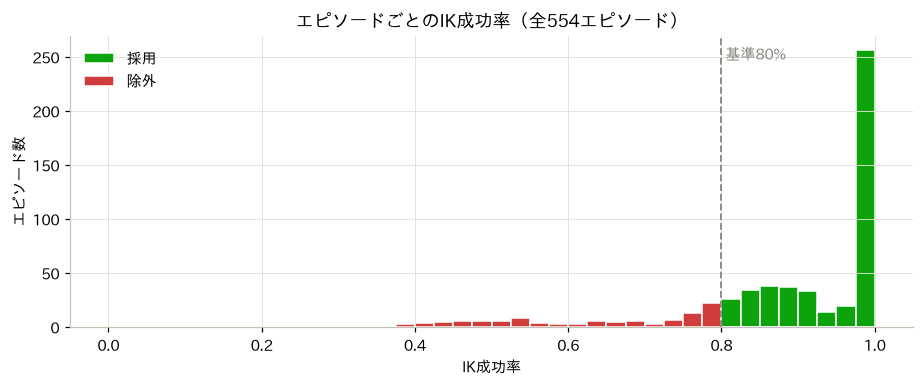

採用: 457エピソード / 除外: 97エピソード
採用エピソードのIK成功フレーム数の合計: 69,555


In [12]:
VALID_RATIO_MIN = 0.80

episode_table = pd.DataFrame({
    "grabette_episode": EPISODE_IDS,
    "n_frames": [len(retarget_results[e]["valid_mask"]) for e in EPISODE_IDS],
    "n_valid": [int(retarget_results[e]["valid_mask"].sum())
                for e in EPISODE_IDS],
})
episode_table["ik_success_ratio"] = (episode_table["n_valid"]
                                     / episode_table["n_frames"])
episode_table["adopted"] = episode_table["ik_success_ratio"] >= VALID_RATIO_MIN

fig, ax = plt.subplots(figsize=(8.5, 3.6))
bins = np.linspace(0, 1, 41)
ax.hist(episode_table.loc[episode_table["adopted"], "ik_success_ratio"],
        bins=bins, color=COLOR_GOOD, edgecolor="white", label="採用")
ax.hist(episode_table.loc[~episode_table["adopted"], "ik_success_ratio"],
        bins=bins, color=COLOR_BAD, edgecolor="white", label="除外")
ax.axvline(VALID_RATIO_MIN, color=COLOR_MUTED, ls="--", lw=1.2)
ax.text(VALID_RATIO_MIN, ax.get_ylim()[1] * 0.92, " 基準80%", color=COLOR_MUTED)
ax.set_xlabel("IK成功率")
ax.set_ylabel("エピソード数")
ax.set_title(f"エピソードごとのIK成功率（全{len(episode_table)}エピソード）")
ax.legend(loc="upper left")
plt.tight_layout()
plt.savefig(OUT_DIR / "04_ik_ratio_histogram.png", bbox_inches="tight")
plt.show()

adopted = episode_table[episode_table["adopted"]].reset_index(drop=True)
n_excluded = int((~episode_table["adopted"]).sum())
print(f"採用: {len(adopted)}エピソード / 除外: {n_excluded}エピソード")
print(f"採用エピソードのIK成功フレーム数の合計: {adopted['n_valid'].sum():,}")

### 2.3 選別結果の目視確認

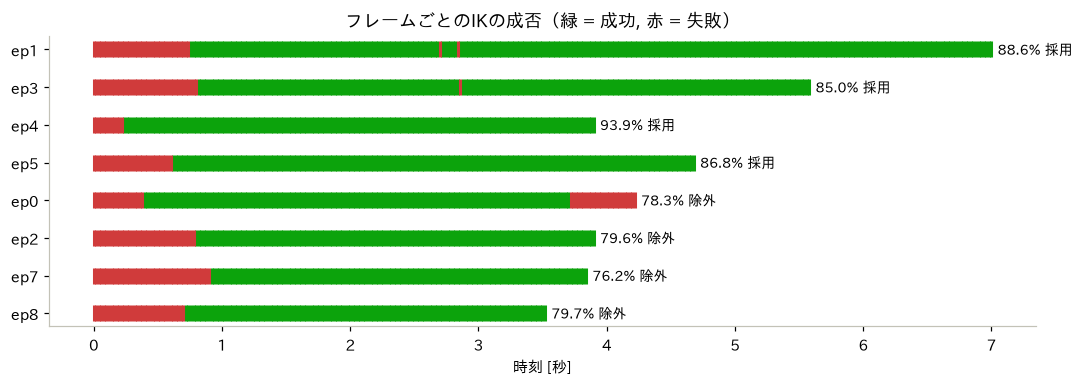

In [13]:
# 採用・除外されたエピソードから数本ずつ取り出し、どのフレームでIKが成功・失敗したかを帯で表示
examples = (list(adopted["grabette_episode"].iloc[:4])
            + list(episode_table.loc[~episode_table["adopted"],
                                     "grabette_episode"].iloc[:4]))
fig, ax = plt.subplots(figsize=(10, 3.6))
for row, episode_id in enumerate(examples):
    mask = retarget_results[episode_id]["valid_mask"]
    t = np.arange(len(mask)) / GRABETTE_FPS
    ax.scatter(t[mask], np.full(mask.sum(), row), marker="|", s=120,
               color=COLOR_GOOD)
    ax.scatter(t[~mask], np.full((~mask).sum(), row), marker="|", s=120,
               color=COLOR_BAD)
    ratio = mask.mean()
    verdict = "採用" if ratio >= VALID_RATIO_MIN else "除外"
    ax.text(t[-1] + 0.05, row, f"{ratio:.1%} {verdict}", va="center",
            fontsize=9)
ax.set_yticks(range(len(examples)), [f"ep{e}" for e in examples])
ax.invert_yaxis()
ax.set_xlabel("時刻 [秒]")
ax.set_title("フレームごとのIKの成否（緑 = 成功, 赤 = 失敗）")
ax.grid(False)
plt.tight_layout()
plt.savefig(OUT_DIR / "04_ik_timeline_examples.png", bbox_inches="tight")
plt.show()

除外されたエピソードでは、失敗（赤）が長く続く区間がある。採用されたエピソードでは、失敗は始まりの短い区間などに限られる。

## 3. 手首カメラの向きによる追加選別（手首カメラ選別版, DP用）

### 3.1 なぜ選別するのか

Grabetteの手元カメラは、実演の最初から最後まで物体の方を向いているが、変換後のSO-101では、エピソードの始まりのIKの解によって手首が大きく反ることがあり、

その結果、手首カメラが作業空間ではなくロボット自身の腕の方*を向いてしまう。

基本的に、学習後はSO-101の手首カメラ映像を入力にして動作を確認する計画であるるため、このような不適切なデータは可能な限り除外することとした。

### 3.2 手首カメラの向きの測り方

MJCFの手首カメラwrist_camの向きをMuJoCoで計算する。

mujoco_menagerieのso101.xmlの初期設定では、カメラは真横を向いてしまうため
グリッパーの先の方向を向くようにeuler="0 0 0"に直し、視野角を90度に広げたモデルを作って使う。

今回用意した向きのlook_Z関数は、カメラの視線方向の上下成分を示す（−1 = 真下、0 = 水平、+1 = 真上）。
各エピソードの最初のIK成功フレームでlook_Zを計算し、look_Z > −0.30（ほぼ水平か、それより上）なら除外することとする

In [14]:
# ============================================================
# 手首カメラの向きを直したSO-101モデルを作る
# ============================================================
import xml.etree.ElementTree as ET

import mujoco

WRISTCAM_DIR = OUT_DIR / "04_wristcam_model"
WRISTCAM_DIR.mkdir(parents=True, exist_ok=True)

tree = ET.parse(MJCF_PATH)
xml_root = tree.getroot()
# 形状データ（STL）の場所を絶対パスにして、別の場所に保存しても読めるようにする
xml_root.find("compiler").set("meshdir", str(MJCF_PATH.parent / "assets"))
for cam in xml_root.iter("camera"):
    if cam.get("name") == "wrist_cam":
        # 焦点距離で視野を決める設定は、視野角fovyと同時に使えないため取り除く
        for attr in ("sensorsize", "focal", "focalpx"):
            cam.attrib.pop(attr, None)
        cam.set("fovy", "90")         # 視野角90度（広角）
        cam.set("euler", "0 0 0")     # グリッパーの先の方向を向く
WRISTCAM_ROBOT = WRISTCAM_DIR / "so101_wristcam.xml"
tree.write(WRISTCAM_ROBOT)

# 描画用に、床と照明を含むシーン（scene.xml）から上のモデルを読み込むようにする
WRISTCAM_SCENE = WRISTCAM_DIR / "scene_wristcam.xml"
WRISTCAM_SCENE.write_text(SCENE_PATH.read_text().replace(
    'file="so101.xml"', f'file="{WRISTCAM_ROBOT}"'))

cam_model = mujoco.MjModel.from_xml_path(str(WRISTCAM_ROBOT))
cam_data = mujoco.MjData(cam_model)
WRIST_CAM_ID = mujoco.mj_name2id(cam_model, mujoco.mjtObj.mjOBJ_CAMERA,
                                 "wrist_cam")


def wrist_look_z(q):
    """
    関節角qのときの手首カメラの視線方向の上下成分（look_Z）を返す。

    MuJoCoのカメラは自身の−Z方向を見ている。cam_xmatはカメラの向きを表す
    3×3行列を行優先で9個に並べたもので、その最後の値がカメラのZ軸の上下成分である。
    視線は−Z方向なので、符号を反転したものが視線の上下成分になる。
    """
    cam_data.qpos[:6] = q
    # mj_forwardまで計算しないと、カメラの向き（cam_xmat）が更新されない
    mujoco.mj_forward(cam_model, cam_data)
    return float(-cam_data.cam_xmat[WRIST_CAM_ID][8])

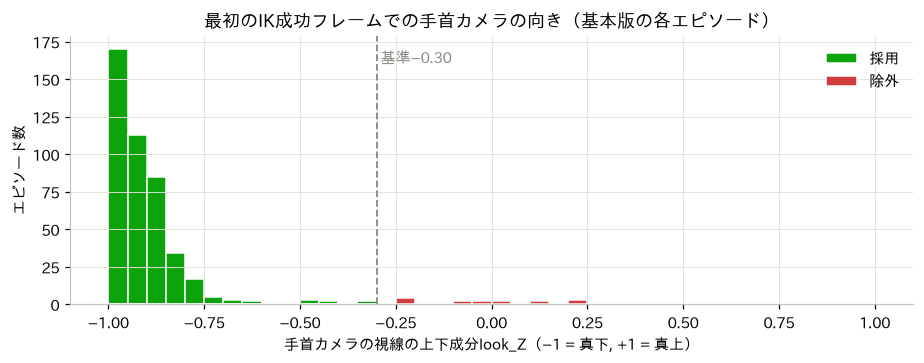

手首カメラの向きで除外: 20エピソード
手首カメラ選別版: 437エピソード, 66,467フレーム


In [15]:
LOOK_Z_MAX = -0.30

look_z = []
for episode_id in adopted["grabette_episode"]:
    result = retarget_results[episode_id]
    first_valid = np.where(result["valid_mask"])[0][0]
    look_z.append(wrist_look_z(result["joint_angles"][first_valid]))
adopted["look_z"] = look_z
adopted["wristcam_ok"] = adopted["look_z"] <= LOOK_Z_MAX

fig, ax = plt.subplots(figsize=(8.5, 3.4))
bins = np.linspace(-1, 1, 41)
ax.hist(adopted.loc[adopted["wristcam_ok"], "look_z"], bins=bins,
        color=COLOR_GOOD, edgecolor="white", label="採用")
ax.hist(adopted.loc[~adopted["wristcam_ok"], "look_z"], bins=bins,
        color=COLOR_BAD, edgecolor="white", label="除外")
ax.axvline(LOOK_Z_MAX, color=COLOR_MUTED, ls="--", lw=1.2)
ax.text(LOOK_Z_MAX, ax.get_ylim()[1] * 0.9, " 基準−0.30", color=COLOR_MUTED)
ax.set_xlabel("手首カメラの視線の上下成分look_Z（−1 = 真下, +1 = 真上）")
ax.set_ylabel("エピソード数")
ax.set_title("最初のIK成功フレームでの手首カメラの向き（基本版の各エピソード）")
ax.legend(loc="upper right")
plt.tight_layout()
plt.savefig(OUT_DIR / "04_wristcam_look_z.png", bbox_inches="tight")
plt.show()

adopted_wristcam = adopted[adopted["wristcam_ok"]].reset_index(drop=True)
print(f"手首カメラの向きで除外: {(~adopted['wristcam_ok']).sum()}エピソード")
print(f"手首カメラ選別版: {len(adopted_wristcam)}エピソード, "
      f"{adopted_wristcam['n_valid'].sum():,}フレーム")

### 3.3 選別結果の目視確認

採用・除外されたエピソードそれぞれについて、最初のIK成功フレームでのSO-101の手首カメラ映像を描画する。
同じ時刻のGrabetteの手元カメラ映像と並べる。

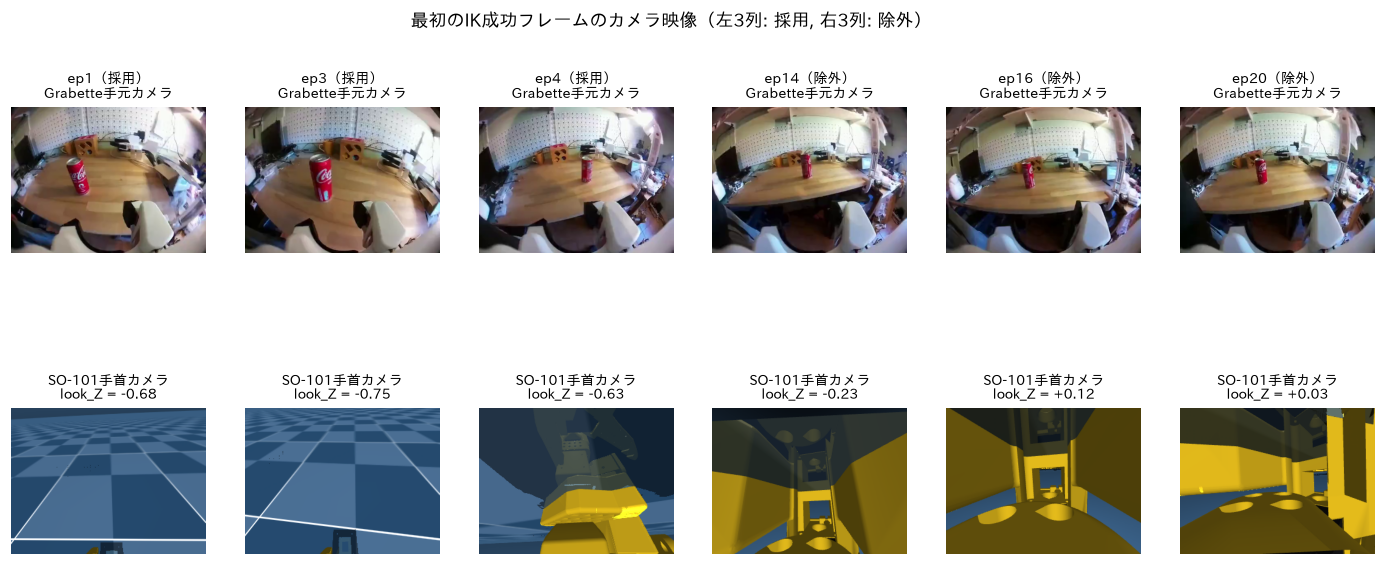

In [16]:
scene_model = mujoco.MjModel.from_xml_path(str(WRISTCAM_SCENE))
scene_data = mujoco.MjData(scene_model)


def render_wrist_view(q, height=240, width=320):
    """関節角qのときのSO-101の手首カメラ映像を描画する。"""
    scene_data.qpos[:6] = q
    mujoco.mj_forward(scene_model, scene_data)
    with mujoco.Renderer(scene_model, height=height, width=width) as renderer:
        renderer.update_scene(scene_data, camera="wrist_cam")
        return renderer.render().copy()


kept = list(adopted.loc[adopted["wristcam_ok"], "grabette_episode"].iloc[:3])
dropped = list(adopted.loc[~adopted["wristcam_ok"],
                           "grabette_episode"].iloc[:3])
fig, axes = plt.subplots(2, 6, figsize=(16, 6.0),
                         gridspec_kw={"hspace": 0.45})
for col, episode_id in enumerate(kept + dropped):
    result = retarget_results[episode_id]
    first_valid = int(np.where(result["valid_mask"])[0][0])
    human = grabette_video_frames(episode_id, [first_valid])[0]
    robot = render_wrist_view(result["joint_angles"][first_valid])
    verdict = "採用" if col < 3 else "除外"
    lz = float(adopted.loc[adopted["grabette_episode"] == episode_id,
                           "look_z"].iloc[0])
    axes[0, col].imshow(human)
    axes[0, col].set_title(f"ep{episode_id}（{verdict}）\nGrabette手元カメラ",
                           fontsize=9)
    axes[1, col].imshow(robot)
    axes[1, col].set_title(f"SO-101手首カメラ\nlook_Z = {lz:+.2f}",
                           fontsize=9)
for ax in axes.ravel():
    ax.axis("off")
plt.suptitle("最初のIK成功フレームのカメラ映像（左3列: 採用, 右3列: 除外）",
             y=0.98)
plt.savefig(OUT_DIR / "04_wristcam_views.png", bbox_inches="tight")
plt.show()

除外されたエピソードでは、手首カメラは横や上を向き、画面の大部分にロボット自身の腕が写る傾向が顕著である。

一方、採用されたep4は下向き（look_Z = −0.63）だが、画面の半分ほどにロボット自身の腕が写っている。
ep4は始まりで肩が大きく横に回った姿勢（shoulder_panが約110度）から始まるためで、look_Zはカメラの上下の向きだけを見る指標ゆえ、このような場合は除外できない。

本件においても、一部このようなノイズデータがデータセットに含まれている点に留意。

## 4. 学習用の画像を取り出す

学習する方策は、手元カメラの画像と関節角を入力にして、次の動作を予測する。
そこで各採用エピソードについて、**IKが成功したフレームと同じ時刻の画像** を取り出す。

- 取り出す時刻: エピソードの開始時刻 + フレーム番号 / 50 fps（数値データと映像は同じ50 fps）
- 画像サイズ: 学習に使う160 × 160画素に縮小する（縮小方法はOpenCVのINTER_AREA）

IKが失敗したフレームは関節角が無いので、画像も取り出さない。関節角と画像は常に1対1で対応する。

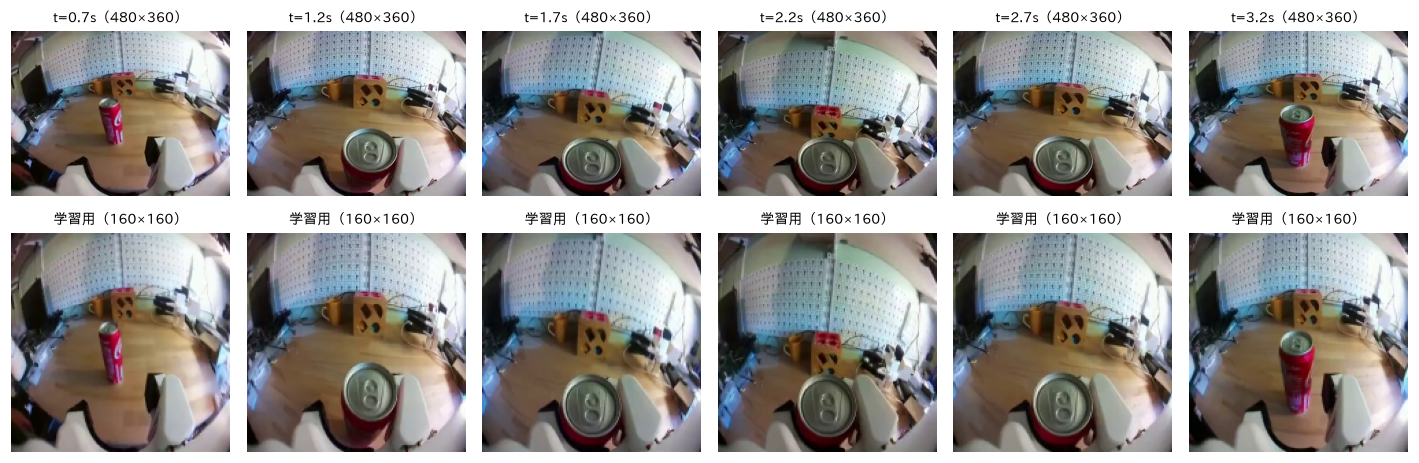

In [17]:
import cv2

IMAGE_SIZE = (160, 160)        # (幅, 高さ)


def extract_training_images(episode_id, valid_mask):
    """IK成功フレームの画像を取り出し、160×160に縮小して(N, 160, 160, 3)で返す。"""
    frame_ids = np.where(valid_mask)[0]
    frames = grabette_video_frames(episode_id, frame_ids)
    return np.stack([
        cv2.resize(frame, IMAGE_SIZE, interpolation=cv2.INTER_AREA)
        for frame in frames
    ])


# 例: エピソード10の画像（元の解像度と、縮小後）
sample_ep = 10
sample_mask = retarget_results[sample_ep]["valid_mask"]
sample_ids = np.where(sample_mask)[0][::25][:6]
originals = grabette_video_frames(sample_ep, sample_ids)
small = extract_training_images(sample_ep, sample_mask)[::25][:6]

fig, axes = plt.subplots(2, len(sample_ids), figsize=(13, 4.4))
for k, t in enumerate(sample_ids):
    axes[0, k].imshow(originals[k])
    axes[0, k].set_title(f"t={t / GRABETTE_FPS:.1f}s（480×360）", fontsize=9)
    axes[1, k].imshow(small[k])
    axes[1, k].set_title("学習用（160×160）", fontsize=9)
for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout()
plt.savefig(OUT_DIR / "04_training_images.png", bbox_inches="tight")
plt.show()

160 × 160に縮小しても、物体（缶）とグリッパーの指の位置関係ははっきり読み取れる。

## 5. LeRobot v3.0形式で保存する

### 5.1 保存形式

lerobot 0.6.1はLeRobot v3.0形式のデータセットのみ受け付ける

```
outputs/so101_lerobot_dataset/              （手首カメラ選別版も同じ構成）
  data/chunk-000/file-000.parquet           全エピソードの数値データ（1行 = 1フレーム）
  videos/observation.image/chunk-000/
      file-000.mp4, file-001.mp4, ...       画像（1エピソード = 1ファイル）
  meta/info.json                            データの項目・形・fpsなどの説明
  meta/tasks.parquet                        タスクの説明文
  meta/episodes/chunk-000/file-000.parquet  エピソードごとの範囲・統計・動画の位置
  meta/stats.json                           全体の統計（学習時の正規化に使われる）
```

### 5.2 保存する項目

| 項目 | 形 | 内容 |
|---|---|---|
| `observation.state` | (6,) float32 | そのフレームのSO-101関節角[rad]（正規化前） |
| `action` | (6,) float32 | 同じフレームのSO-101関節角[rad]。学習時は「未来のフレームのaction」を予測の目標として読み出す |
| `observation.image` | (3, 160, 160)動画 | そのフレームの手元カメラ画像 |
| `timestamp` | float64 | フレーム番号 / 30 |

In [18]:
# ============================================================
# 保存の設定と補助関数
# ============================================================
import contextlib
import json
import shutil

import av
import pyarrow as pa
import pyarrow.parquet as pq

DATASET_DIR = OUT_DIR / "so101_lerobot_dataset"                 # 基本版（ACT用）
DATASET_WRISTCAM_DIR = OUT_DIR / "so101_lerobot_dataset_wristcam"  # DP用
DATASET_FPS = 30                       # info.jsonに記録するfps（上の説明を参照）
TASK_TEXT = "Pick up the cube"         # 学習時と同じタスク説明文
IMAGE_KEY = "observation.image"

# parquetの列の型（lerobotが読み込むときの型と一致させる）
FRAME_SCHEMA = pa.schema([
    pa.field("episode_index", pa.int64()),
    pa.field("frame_index", pa.int64()),
    pa.field("index", pa.int64()),
    pa.field("task_index", pa.int64()),
    pa.field("timestamp", pa.float64()),
    pa.field("action", pa.list_(pa.float32())),
    pa.field("observation.state", pa.list_(pa.float32())),
])


@contextlib.contextmanager
def suppress_c_stderr():
    """
    C言語レベルの標準エラー出力を一時的に捨てる。

    SVT-AV1エンコーダは、起動のたびに設定内容を標準エラー出力へ直接書き出す。
    Pythonの出力抑制では止められないため、出力先そのものを一時的に/dev/nullに向ける。
    """
    saved = os.dup(2)
    devnull = os.open(os.devnull, os.O_WRONLY)
    os.dup2(devnull, 2)
    os.close(devnull)
    try:
        yield
    finally:
        os.dup2(saved, 2)
        os.close(saved)


def save_episode_video(images, path, fps=DATASET_FPS):
    """
    画像(N, H, W, 3)をmp4に保存する。

    圧縮方式はlerobot 0.6.1の標準と同じAV1（SVT-AV1エンコーダ,
    品質crf=30, 速度preset=12, キーフレーム間隔g=2）とする。
    """
    path.parent.mkdir(parents=True, exist_ok=True)
    n_images, height, width, _ = images.shape
    with suppress_c_stderr(), av.open(str(path), mode="w") as container:
        stream = container.add_stream(
            "libsvtav1", rate=fps,
            options={"crf": "30", "preset": "12", "g": "2"})
        stream.width = width
        stream.height = height
        stream.pix_fmt = "yuv420p"
        for image in images:
            frame = av.VideoFrame.from_ndarray(image, format="rgb24")
            for packet in stream.encode(frame):
                container.mux(packet)
        for packet in stream.encode():          # 残りのデータを書き出す
            container.mux(packet)


def per_episode_stats(values):
    """エピソード内の関節角(N, 6)の平均・標準偏差・最小・最大・個数を返す。"""
    return {
        "mean": values.mean(axis=0).tolist(),
        "std": values.std(axis=0).tolist(),
        "min": values.min(axis=0).tolist(),
        "max": values.max(axis=0).tolist(),
        "count": [len(values)],
    }


def aggregate_stats(stats_list):
    """
    エピソードごとの統計をまとめて、データセット全体の統計にする。

    平均はフレーム数で重み付けした平均とする。
    分散は「各エピソードの分散 + 各エピソードの平均と全体平均の差の2乗」を
    フレーム数で重み付けして平均する（全フレームをまとめて計算した場合と同じ値になる）。
    """
    means = np.stack([np.array(s["mean"]) for s in stats_list])
    stds = np.stack([np.array(s["std"]) for s in stats_list])
    counts = np.array([s["count"][0] for s in stats_list], dtype=float)
    weights = counts[:, None]
    total = counts.sum()
    mean = (means * weights).sum(axis=0) / total
    var = ((stds ** 2 + (means - mean) ** 2) * weights).sum(axis=0) / total
    return {
        "min": np.stack([s["min"] for s in stats_list]).min(axis=0).tolist(),
        "max": np.stack([s["max"] for s in stats_list]).max(axis=0).tolist(),
        "mean": mean.tolist(),
        "std": np.sqrt(var).tolist(),
        "count": [int(total)],
    }


def scalar_feature(dtype):
    """info.json用: 1フレームに1つの値を持つ項目の説明。"""
    return {"dtype": dtype, "shape": [1], "names": None, "fps": DATASET_FPS}

In [19]:
# ============================================================
# データセット1つ分を保存する関数
# ============================================================
def export_dataset(dataset_dir, episode_ids, make_video):
    """
    指定したエピソードを、LeRobot v3.0形式でdataset_dirに保存する。

    episode_ids : データセットに入れるGrabetteのエピソード番号の並び
                  （並び順がデータセット内のエピソード番号0, 1, 2, ... になる）
    make_video  : make_video(データセット内の番号, Grabetteの番号, 保存先mp4)
                  を呼ぶと、そのエピソードの画像をmp4に保存し、画像の枚数を返す関数
    戻り値      : (エピソード数, 総フレーム数, エピソードごとのメタ情報の並び)
    """
    # 出力先を作り直す（以前の出力が残っていると、古いファイルが混ざるため）
    if dataset_dir.exists():
        shutil.rmtree(dataset_dir)
    video_dir = dataset_dir / "videos" / IMAGE_KEY / "chunk-000"
    meta_dir = dataset_dir / "meta"
    for directory in [dataset_dir / "data" / "chunk-000", video_dir,
                      meta_dir / "episodes" / "chunk-000"]:
        directory.mkdir(parents=True, exist_ok=True)

    frame_rows = []      # data/chunk-000/file-000.parquetの各行
    episode_rows = []    # meta/episodes/chunk-000/file-000.parquetの各行
    episode_stats = []   # エピソードごとの統計（全体の統計を作るため）
    global_index = 0     # データセット全体での通し番号

    for dataset_episode, grabette_episode in enumerate(episode_ids):
        result = retarget_results[grabette_episode]
        # IK成功フレームの関節角だけを、時刻順に取り出す
        q_valid = result["joint_angles"][result["valid_mask"]].astype(
            np.float32)
        n_valid = len(q_valid)
        n_images = make_video(dataset_episode, grabette_episode,
                              video_dir / f"file-{dataset_episode:03d}.mp4")
        # 画像の枚数と関節角の行数が一致していることを確かめる（1対1対応の確認）
        assert n_images == n_valid

        for frame_index, q in enumerate(q_valid):
            q_list = q.tolist()
            frame_rows.append({
                "episode_index": dataset_episode,
                "frame_index": frame_index,
                "index": global_index + frame_index,
                "task_index": 0,
                "timestamp": float(frame_index) / DATASET_FPS,
                "action": q_list,
                "observation.state": q_list,
            })

        stats = per_episode_stats(q_valid)
        episode_stats.append(stats)
        row = {
            "episode_index": dataset_episode,
            "data/chunk_index": 0,
            "data/file_index": 0,
            "dataset_from_index": global_index,
            "dataset_to_index": global_index + n_valid,
            "tasks": [0],
            "length": n_valid,
        }
        for key in ["observation.state", "action"]:
            for name in ["mean", "std", "min", "max", "count"]:
                row[f"stats/{key}/{name}"] = stats[name]
        row.update({
            "meta/episodes/chunk_index": 0,
            "meta/episodes/file_index": 0,
            # このエピソードの画像が入っているmp4と、その中での時間範囲
            f"videos/{IMAGE_KEY}/chunk_index": 0,
            f"videos/{IMAGE_KEY}/file_index": dataset_episode,
            f"videos/{IMAGE_KEY}/from_timestamp": 0.0,
            f"videos/{IMAGE_KEY}/to_timestamp": float(n_valid) / DATASET_FPS,
        })
        episode_rows.append(row)
        global_index += n_valid

    total_frames = global_index
    n_episodes = len(episode_ids)

    # 数値データ
    pq.write_table(pa.Table.from_pylist(frame_rows, schema=FRAME_SCHEMA),
                   dataset_dir / "data" / "chunk-000" / "file-000.parquet")
    # タスクの説明文（索引 = 説明文、列task_index = 番号）
    pd.DataFrame({"task_index": [0]},
                 index=pd.Index([TASK_TEXT], name="task")).to_parquet(
        meta_dir / "tasks.parquet")
    # エピソードごとのメタ情報
    pd.DataFrame(episode_rows).to_parquet(
        meta_dir / "episodes" / "chunk-000" / "file-000.parquet", index=False)
    # 全体の統計（actionとobservation.stateは同じ値なので、同じ統計になる）
    global_stats = {"action": aggregate_stats(episode_stats),
                    "observation.state": aggregate_stats(episode_stats)}
    with open(meta_dir / "stats.json", "w") as f:
        json.dump(global_stats, f, indent=2)

    # データセットの説明（info.json）
    joint_feature = {"dtype": "float32", "shape": [6], "names": JOINT_NAMES,
                     "fps": DATASET_FPS}
    info = {
        "codebase_version": "v3.0",
        "fps": DATASET_FPS,
        "robot_type": "so101",
        "tasks": [{"task_index": 0, "task": TASK_TEXT}],
        "features": {
            "episode_index": scalar_feature("int64"),
            "frame_index": scalar_feature("int64"),
            "index": scalar_feature("int64"),
            "task_index": scalar_feature("int64"),
            "timestamp": scalar_feature("float64"),
            "action": dict(joint_feature),
            "observation.state": dict(joint_feature),
            # 画像は (チャンネル, 高さ, 幅) の順で形を記録する
            IMAGE_KEY: {
                "dtype": "video",
                "shape": [3, IMAGE_SIZE[1], IMAGE_SIZE[0]],
                "names": ["channels", "height", "width"],
                "info": {
                    "video.fps": float(DATASET_FPS),
                    "video.codec": "av1",
                    "video.pix_fmt": "yuv420p",
                    "video.is_depth_map": False,
                    "has_audio": False,
                },
            },
        },
        "total_episodes": n_episodes,
        "total_frames": total_frames,
        "total_tasks": 1,
        "chunks_size": 1000,
        "data_files_size_in_mb": 100,
        "video_files_size_in_mb": 200,
        "data_path": ("data/chunk-{chunk_index:03d}/"
                      "file-{file_index:03d}.parquet"),
        "video_path": ("videos/{video_key}/chunk-{chunk_index:03d}/"
                       "file-{file_index:03d}.mp4"),
        "splits": {"train": f"0:{total_frames}"},
    }
    with open(meta_dir / "info.json", "w") as f:
        json.dump(info, f, indent=2)
    return n_episodes, total_frames, episode_rows

### 5.3 基本版（ACT用）の保存

画像の取り出しは1エピソードあたり1秒程度で終わるため、並列化せずに順番に処理する。
（動画の読み込みライブラリが内部で使うスレッドと、プロセスの複製（fork）を組み合わせると、処理が止まることがあるためである。）

In [20]:
def video_from_source(dataset_episode, grabette_episode, mp4_path):
    """Grabette映像から画像を取り出してmp4に保存し、画像の枚数を返す。"""
    images = extract_training_images(
        grabette_episode, retarget_results[grabette_episode]["valid_mask"])
    save_episode_video(images, mp4_path)
    return len(images)


start = time.time()
n_episodes, total_frames, episode_rows = export_dataset(
    DATASET_DIR, list(adopted["grabette_episode"]), video_from_source)
print(f"基本版: {n_episodes}エピソード, {total_frames:,}フレーム "
      f"（{time.time() - start:.0f}秒）")

基本版: 457エピソード, 69,555フレーム （315秒）


### 5.4 手首カメラ選別版（DP用）の保存

手首カメラ選別版の各エピソードは、基本版にも同じものが含まれている（同じ画像・同じ関節角）。
そこで画像は取り出し直さず、基本版で保存したmp4をコピーして使う。

In [21]:
# Grabetteのエピソード番号 → 基本版の中での番号
base_index = {int(e): k for k, e in enumerate(adopted["grabette_episode"])}
base_video_dir = DATASET_DIR / "videos" / IMAGE_KEY / "chunk-000"


def video_from_base(dataset_episode, grabette_episode, mp4_path):
    """基本版の同じエピソードのmp4をコピーし、画像の枚数を返す。"""
    base_episode = base_index[int(grabette_episode)]
    source = base_video_dir / f"file-{base_episode:03d}.mp4"
    shutil.copyfile(source, mp4_path)
    with av.open(str(mp4_path)) as container:
        return sum(1 for _ in container.decode(video=0))


start = time.time()
n_episodes_wc, total_frames_wc, episode_rows_wc = export_dataset(
    DATASET_WRISTCAM_DIR, list(adopted_wristcam["grabette_episode"]),
    video_from_base)
print(f"手首カメラ選別版: {n_episodes_wc}エピソード, {total_frames_wc:,}フレーム "
      f"（{time.time() - start:.0f}秒）")

# Grabetteのエピソード番号と、各データセット内の番号の対応表を残す
mapping = adopted.assign(dataset_episode=range(n_episodes))
wristcam_index = {int(e): k for k, e
                  in enumerate(adopted_wristcam["grabette_episode"])}
mapping["dataset_episode_wristcam"] = [
    wristcam_index.get(int(e), -1) for e in mapping["grabette_episode"]]
mapping.to_csv(OUT_DIR / "04_episode_mapping.csv", index=False)

for directory in [DATASET_DIR, DATASET_WRISTCAM_DIR]:
    video_files = list((directory / "videos" / IMAGE_KEY / "chunk-000").glob(
        "*.mp4"))
    video_mb = sum(p.stat().st_size for p in video_files) / 1e6
    print(f"{directory.name}: 動画{len(video_files)}本（{video_mb:.0f} MB）")

手首カメラ選別版: 437エピソード, 66,467フレーム （37秒）
so101_lerobot_dataset: 動画457本（185 MB）
so101_lerobot_dataset_wristcam: 動画437本（176 MB）


## 6. 保存したデータセットの確認

### 6.1 lerobotで読み込めるか

lerobot 0.6.1のLeRobotDatasetで2つのデータセットを読み込む。1サンプルを取り出せるかを確かめる。

In [22]:
from lerobot.datasets.lerobot_dataset import LeRobotDataset

dp_delta = {
    "observation.state": [-1 / DATASET_FPS, 0.0],     # 直前と現在のフレーム
    IMAGE_KEY: [-1 / DATASET_FPS, 0.0],
    "action": [k / DATASET_FPS for k in range(1, 17)],  # 1〜16フレーム先
}
act_delta = {"action": [k / DATASET_FPS for k in range(0, 16)]}  # 現在〜15先

loaded = {}
for name, directory, delta in [("ACT用（基本版）", DATASET_DIR, act_delta),
                               ("DP用（手首カメラ選別版）",
                                DATASET_WRISTCAM_DIR, dp_delta)]:
    dataset = LeRobotDataset(
        repo_id="local/so101",      # ローカルのデータセットなので任意の名前でよい
        root=directory,
        delta_timestamps=delta,
        video_backend="pyav",
    )
    loaded[name] = dataset
    sample = dataset[100]
    print(f"{name}: {dataset.num_episodes}エピソード, {len(dataset):,}サンプル")
    for key in ["observation.state", IMAGE_KEY, "action"]:
        print(f"    {key:18s} 形{tuple(sample[key].shape)}")

ACT用（基本版）: 457エピソード, 69,555サンプル
    observation.state  形(6,)
    observation.image  形(3, 160, 160)
    action             形(16, 6)


DP用（手首カメラ選別版）: 437エピソード, 66,467サンプル
    observation.state  形(2, 6)
    observation.image  形(2, 3, 160, 160)
    action             形(16, 6)


### 6.2 データセット全体の統計（正規化前）

学習側の正規化は、この統計（`meta/stats.json`）を使って行われる。

In [23]:
def load_stats_table(directory):
    """meta/stats.jsonのactionの統計を、関節ごとの表にする。"""
    with open(directory / "meta" / "stats.json") as f:
        stats = json.load(f)["action"]
    return pd.DataFrame({key: np.round(stats[key], 4)
                         for key in ["min", "max", "mean", "std"]},
                        index=JOINT_NAMES)


stats_base = load_stats_table(DATASET_DIR)
stats_wristcam = load_stats_table(DATASET_WRISTCAM_DIR)
pd.concat({"基本版（ACT用）": stats_base,
           "手首カメラ選別版（DP用）": stats_wristcam}, axis=1)

基本版（ACT用）                         手首カメラ選別版（DP用）                  \
                    min     max    mean     std           min     max    mean   
shoulder_pan    -1.8627  1.9198 -0.0670  0.2246       -1.8627  1.9198 -0.0730   
shoulder_lift   -1.7453  1.1685 -0.6753  0.8214       -1.7453  1.0640 -0.7046   
elbow_flex      -0.3360  1.6900  1.4142  0.1899       -0.3360  1.6900  1.4171   
wrist_flex      -1.6581  1.6581 -0.2785  1.2680       -1.6581  1.6581 -0.2508   
wrist_roll      -1.5708 -1.5708 -1.5708  0.0000       -1.5708 -1.5708 -1.5708   
gripper          0.0000  1.7453  0.9333  0.6935        0.0000  1.7453  0.9349   

                       
                  std  
shoulder_pan   0.2176  
shoulder_lift  0.8157  
elbow_flex     0.1892  
wrist_flex     1.2667  
wrist_roll     0.0000  
gripper        0.6971

05にて学習時の正規化と学習を扱う